In [1]:
# Import core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot style configuration for the video
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

# Fix the seed for reproducible simulations
np.random.seed(42)

## Weak Stationarity

For a classical statistical model to make sense, the probabilistic properties of the process must not change over time. 
We distinguish between:
*   **Strict stationarity:** The entire joint distribution of $(X_{t_1}, \dots, X_{t_k})$ is identical to the time-shifted one $(X_{t_1+h}, \dots, X_{t_k+h})$.
*   **Weak (second-order) stationarity:** Only the first two moments of the distribution are required to be constant over time.

A process $\{X_t\}$ is **weakly stationary** if:
1.  **Constant mean:** $\mathbb{E}[X_t] = \mu$ (independent of $t$)
2.  **Constant variance:** $\text{Var}(X_t) = \mathbb{E}[(X_t - \mu)^2] = \sigma^2 < \infty$ (independent of $t$)
3.  **Autocovariance depending only on the lag $h$:** $\gamma(t, t+h) = \text{Cov}(X_t, X_{t+h}) = \gamma_h$ (independent of $t$)


# The Ergodicity Hypothesis

A problem arises when we compute the moments of a stochastic process (such as the mean $\mathbb{E}[X_t]$). 
Mathematically, the expected value is computed over all possible realizations of the process at time $t$ (ensemble average). 
But in reality, **we observe only one timeline (a single historical trajectory)**. 

How can we estimate the mean and variance if we don't have parallel universes?

This is where the concept of **Ergodicity** comes in. A stationary process is said to be *ergodic in the mean* if the **time average** over a single large sample converges (as $T \to \infty$) to the **ensemble average** (the theoretical expected value):

$$ \bar{x} = \frac{1}{T} \sum_{t=1}^T x_t \xrightarrow{p} \mathbb{E}[X_t] = \mu $$

If a time series is ergodic, "a sample observed for a long time tells us everything there is to know about the statistical population of the process". 
Stationarity guarantees that the distribution does not change; ergodicity guarantees that we can measure it by watching time go by.

## White Noise vs Random Walk

To understand stationarity, we simulate the two opposite extremes:
1.  **White Noise $\epsilon_t \sim WN(0, \sigma^2)$:** Uncorrelated random variables with zero mean and constant variance. It is **stationary**.
2.  **Random Walk $X_t = X_{t-1} + \epsilon_t$:** Each value is the previous one plus white noise. Its variance grows linearly with time ($\text{Var}(X_t) = t \sigma^2$). It is **non-stationary**.

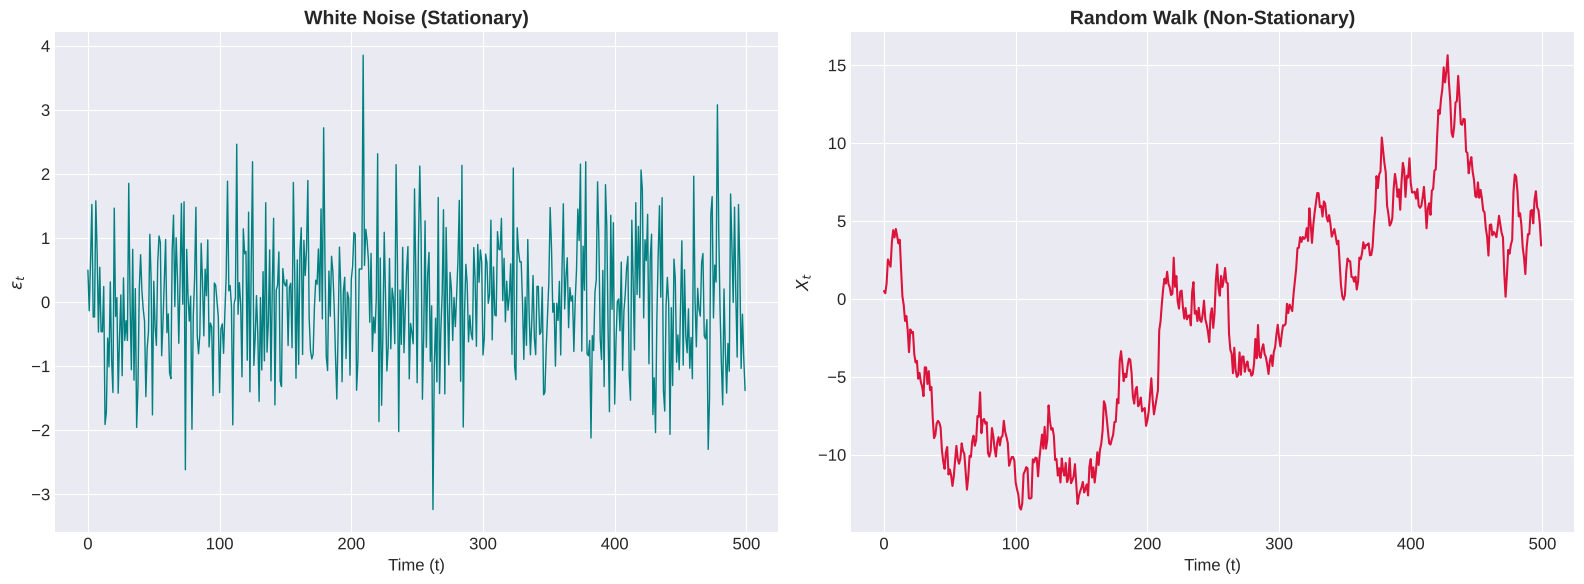

In [2]:
# Simulate 500 observations
n = 500

# 1. White Noise (Gaussian)
# epsilon_t ~ N(0, 1)
white_noise = np.random.normal(loc=0, scale=1, size=n)

# 2. Random Walk
# X_t = X_{t-1} + epsilon_t (it is the cumulative sum of a White Noise)
random_walk = np.cumsum(white_noise)

# Side-by-side comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot White Noise
ax1.plot(white_noise, color='teal', linewidth=1)
ax1.set_title('White Noise (Stationary)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Time (t)')
ax1.set_ylabel(r'$\epsilon_t$')

# Plot Random Walk
ax2.plot(random_walk, color='crimson', linewidth=1.5)
ax2.set_title('Random Walk (Non-Stationary)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Time (t)')
ax2.set_ylabel(r'$X_t$')

plt.tight_layout()
plt.show()

## Autocorrelation (ACF) and Partial Autocorrelation (PACF)

To quantify the temporal "memory" of a weakly stationary stochastic process $X_t$ and understand its internal structure, we use two fundamental diagnostic tools: the **Autocorrelation Function (ACF)** and the **Partial Autocorrelation Function (PACF)**.

---

### Autocorrelation Function (ACF)

Let $\{X_t\}$ be a weakly stationary process with mean $\mu = \mathbb{E}[X_t]$.
The **autocovariance** at lag $h \in \mathbb{Z}$ is defined as:
$$ \gamma_h = \text{Cov}(X_t, X_{t+h}) = \mathbb{E}[(X_t - \mu)(X_{t+h} - \mu)] $$

The dimensionless **Autocorrelation Function (ACF)** $\rho_h$ is obtained by normalizing the autocovariance by the process variance $\gamma_0 = \text{Var}(X_t)$:
$$ \rho_h = \frac{\gamma_h}{\gamma_0} = \frac{\text{Cov}(X_t, X_{t+h})}{\text{Var}(X_t)} $$

#### **Fundamental properties of the ACF:**
1. **Normalization:** $\rho_0 = 1$.
2. **Boundedness:** $|\rho_h| \le 1, \quad \forall h \in \mathbb{Z}$.
3. **Symmetry:** $\rho_h = \rho_{-h}$ (the autocorrelation depends only on the time distance $|h|$).
4. **Non-Negative Definite Matrix:** By Bochner's Theorem, the sequence $\{\gamma_h\}$ must ensure that the autocovariance matrix is positive semidefinite.

#### **Sample Estimator ($r_h$):**
Given an observed time series $(X_1, X_2, \dots, X_T)$ with sample mean $\bar{X} = \frac{1}{T}\sum_{t=1}^T X_t$, the sample autocorrelation is estimated as:
$$ r_h = \hat{\rho}_h = \frac{\sum_{t=1}^{T-h} (X_t - \bar{X})(X_{t+h} - \bar{X})}{\sum_{t=1}^T (X_t - \bar{X})^2} $$
*(Note: Dividing by $T$ rather than $T-h$ mathematically guarantees that the sample autocorrelation matrix is positive semidefinite).*

---

### Partial Autocorrelation Function (PACF)

The simple autocorrelation $\rho_h$ measures the total correlation between $X_t$ and $X_{t-h}$. However, this correlation includes both the direct effect of $X_{t-h}$ on $X_t$ and the **indirect effects** propagated through all the intermediate lags ($X_{t-1}, X_{t-2}, \dots, X_{t-h+1}$).

The **Partial Autocorrelation (PACF)**, denoted $\phi_{hh}$, measures only the **direct linear relationship** between $X_t$ and $X_{t-h}$, completely removing the influence of the intermediate variables.

#### **Formal Definition via Autoregressive Regression:**
Consider the linear regression of $X_t$ on its first $h$ lags:
$$ X_t = \phi_{h1} X_{t-1} + \phi_{h2} X_{t-2} + \dots + \phi_{hh} X_{t-h} + e_t $$

The PACF at lag $h$ is defined exactly as **the last estimated coefficient** $\phi_{hh}$ of this order-$h$ linear regression.

#### **Matrix Solution (Yule-Walker System):**
The coefficients are obtained by solving the Yule-Walker equations:
$$ \begin{pmatrix} 1 & \rho_1 & \dots & \rho_{h-1} \\ \rho_1 & 1 & \dots & \rho_{h-2} \\ \vdots & \vdots & \ddots & \vdots \\ \rho_{h-1} & \rho_{h-2} & \dots & 1 \end{pmatrix} \begin{pmatrix} \phi_{h1} \\ \phi_{h2} \\ \vdots \\ \phi_{hh} \end{pmatrix} = \begin{pmatrix} \rho_1 \\ \rho_2 \\ \vdots \\ \rho_h \end{pmatrix} $$

By **Cramer's Rule**, the PACF $\phi_{hh}$ is the ratio of determinants:
$$ \phi_{hh} = \frac{\det(P_h^*)}{\det(P_h)} $$
where $P_h$ is the $h \times h$ autocorrelation matrix, and $P_h^*$ is the matrix $P_h$ with its last column replaced by the vector $(\rho_1, \rho_2, \dots, \rho_h)^T$.

---

### Cut-Off Rules

In the Box-Jenkins identification framework, the joint behavior of ACF and PACF reveals the nature of the stochastic process:

| Process Type | ACF ($\rho_h$) | PACF ($\phi_{hh}$) |
| :--- | :--- | :--- |
| **White Noise $WN(0, \sigma^2)$** | $\rho_h = 0 \quad (\forall h \ge 1)$ | $\phi_{hh} = 0 \quad (\forall h \ge 1)$ |
| **Autoregressive $AR(p)$** | Exponential or damped sinusoidal decay | **Sharp cut-off after lag $p$** ($\phi_{hh} = 0, \forall h > p$) |
| **Moving Average $MA(q)$** | **Sharp cut-off after lag $q$** ($\rho_h = 0, \forall h > q$) | Exponential or damped sinusoidal decay |
| **Mixed $ARMA(p,q)$** | Exponential/sinusoidal decay | Exponential/sinusoidal decay |

---

### Statistical Significance and Confidence Intervals

To check whether a sample correlation $r_h$ or $\hat{\phi}_{hh}$ is significantly different from zero, we rely on **Bartlett's Theorem**.

Under the null hypothesis $H_0$ that the process is **White Noise** (or for lags $h$ greater than the order of the process):
$$ \text{Var}(r_h) \approx \frac{1}{T}, \quad \text{Var}(\hat{\phi}_{hh}) \approx \frac{1}{T} $$

Consequently, for sufficiently large $T$, $r_h$ and $\hat{\phi}_{hh}$ are asymptotically distributed as a Normal $\mathcal{N}(0, 1/T)$.
The **95% confidence bands** in correlograms are delimited by the lines:
$$ \pm \frac{1.96}{\sqrt{T}} \approx \pm \frac{2}{\sqrt{T}} $$

If a spike falls outside these bands, the autocorrelation at lag $h$ is **statistically significant** ($p < 0.05$).

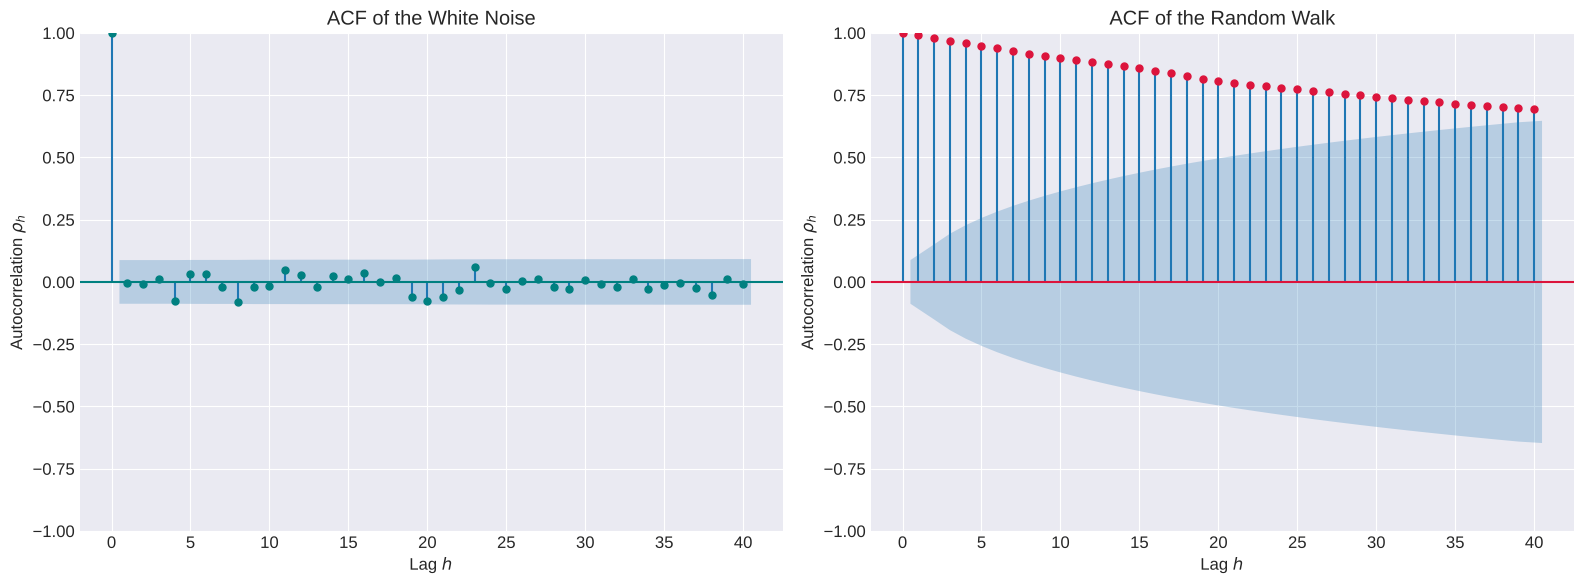

In [3]:
# Plot the correlograms (ACF) for the two processes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ACF per il White Noise
# The blue area represents the 95% confidence interval. 
# If a lag falls inside the blue area, it is not statistically significant.
plot_acf(white_noise, lags=40, ax=ax1, color='teal', title="ACF of the White Noise")
ax1.set_xlabel('Lag $h$')
ax1.set_ylabel(r'Autocorrelation $\rho_h$')

# ACF per il Random Walk
plot_acf(random_walk, lags=40, ax=ax2, color='crimson', title="ACF of the Random Walk")
ax2.set_xlabel('Lag $h$')
ax2.set_ylabel(r'Autocorrelation $\rho_h$')

plt.tight_layout()
plt.show()

### Interpreting the ACF Plots

1.  **White Noise:** At lag 0 the autocorrelation is obviously 1 ($\rho_0=1$). All other lags fall inside the confidence interval (blue band), oscillating around zero. This empirically shows that the variables are uncorrelated: **there is no memory**.
2.  **Random Walk:** The autocorrelation decays very slowly. A current value $X_t$ is strongly correlated with $X_{t-1}, X_{t-2}$, etc. This slow decay (long memory) is the classic visual symptom of **non-stationarity**.